In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/walidnishat/games-data/Games_Dataset_Clean.csv")

df.head()

,title,original price,current price,discount %,review count,tags,platform,release date,metascore,developer,publisher,summary,release year,release month
0,Escape Simulator 2,349.0,279.0,20,3658,"Adventure, Casual, Indie, Simulation, Single-p...","windows, mac",2025-10-27,79.0,Pine Studio,Pine Studio,"Sequel to the best-selling escape room game, b...",2025.0,10.0
1,NEO Scavenger,268.0,268.0,0,4394,"Indie, RPG, Strategy, Single-player, Steam Tra...","windows, mac, linux",2014-12-15,77.0,Blue Bottle Games,Blue Bottle Games,NEO Scavenger is a game where you must survive...,2014.0,12.0
2,ROBOBEAT,318.0,318.0,0,1654,"Action, Adventure, Indie, Single-player, Steam...",windows,2024-05-14,83.0,Simon Fredholm,Kwalee,Keep your trigger finger on the pulse! In rhyt...,2024.0,5.0
3,Devil May Cry 5,860.0,860.0,0,110977,"Action, Single-player, Multi-player, Co-op, On...",windows,2019-03-07,89.0,"CAPCOM Co., Ltd.","CAPCOM Co., Ltd.","The ultimate Devil Hunter is back in style, in...",2019.0,3.0
4,Subnautica,899.0,899.0,0,314047,"Adventure, Indie, Single-player, Steam Achieve...","windows, mac",2018-01-23,87.0,Unknown Worlds Entertainment,Unknown Worlds Entertainment,Descend into the depths of an alien underwater...,2018.0,1.0


In [3]:
df.isnull().sum()

title             0
original price    0
current price     0
discount %        0
review count      0
tags              0
platform          0
release date      0
metascore         0
developer         0
publisher         0
summary           0
release year      0
release month     0
dtype: int64

In [4]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report

In [5]:
threshold = df['review count'].median()

df['popular'] = (df['review count'] > threshold).astype(int)

print("Threshold:", threshold)
print(df['popular'].value_counts())

Threshold: 1556.5
popular
1    1612
0    1612
Name: count, dtype: int64


In [6]:
features = ['original price', 'current price', 'metascore', 'discount %', 'release year']

df = df.dropna(subset=features + ['popular'])

X = df[features]
y = df['popular']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

In [10]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

In [11]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)   # NOTE: no scaling needed

rf_pred = rf_model.predict(X_test)

In [12]:
print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

SVM Accuracy: 0.7116279069767442
Logistic Regression Accuracy: 0.6759689922480621
Random Forest Accuracy: 0.7131782945736435


In [13]:
from sklearn.metrics import confusion_matrix

In [14]:
print("\n--- SVM ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred))
print("\nClassification Report:")
print(classification_report(y_test, svm_pred))


print("\n--- Logistic Regression ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))
print("\nClassification Report:")
print(classification_report(y_test, lr_pred))


print("\n--- Random Forest ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))


--- SVM ---
Confusion Matrix:
[[222  99]
 [ 87 237]]

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.69      0.70       321
           1       0.71      0.73      0.72       324

    accuracy                           0.71       645
   macro avg       0.71      0.71      0.71       645
weighted avg       0.71      0.71      0.71       645


--- Logistic Regression ---
Confusion Matrix:
[[240  81]
 [128 196]]

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.75      0.70       321
           1       0.71      0.60      0.65       324

    accuracy                           0.68       645
   macro avg       0.68      0.68      0.67       645
weighted avg       0.68      0.68      0.67       645


--- Random Forest ---
Confusion Matrix:
[[219 102]
 [ 83 241]]

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.

In [15]:
results = {
    "SVM": {
        "accuracy": accuracy_score(y_test, svm_pred),
    },
    "Logistic Regression": {
        "accuracy": accuracy_score(y_test, lr_pred),
    },
    "Random Forest": {
        "accuracy": accuracy_score(y_test, rf_pred),
    }
}

for model, metrics in results.items():
    print(model, ":", metrics)


SVM : {'accuracy': 0.7116279069767442}
Logistic Regression : {'accuracy': 0.6759689922480621}
Random Forest : {'accuracy': 0.7131782945736435}


In [16]:
results = {
    "SVM": accuracy_score(y_test, svm_pred),
    "Logistic Regression": accuracy_score(y_test, lr_pred),
    "Random Forest": accuracy_score(y_test, rf_pred)
}

best_model = max(results, key=results.get)
print("\nBest Model:", best_model)


Best Model: Random Forest


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [18]:
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d')
    
    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    
    plt.show()

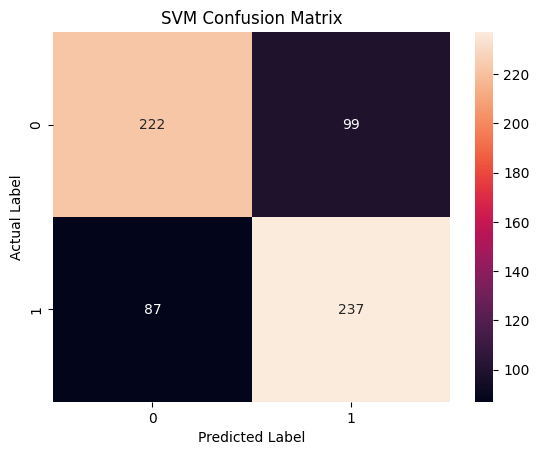

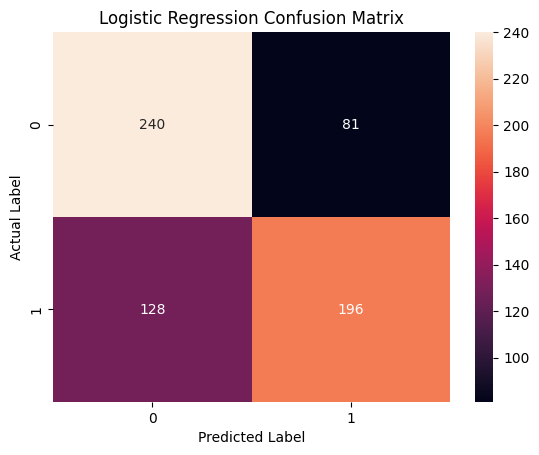

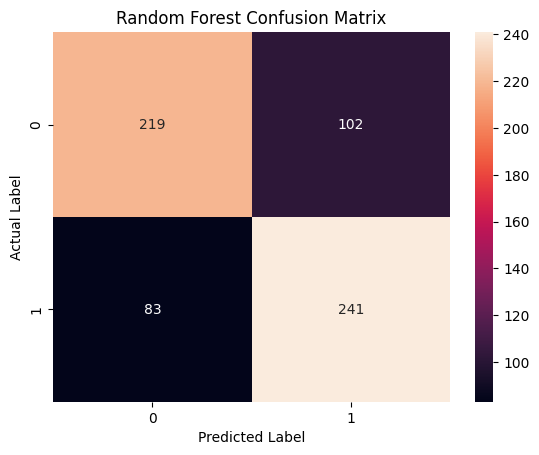

In [19]:
plot_confusion_matrix(y_test, svm_pred, "SVM Confusion Matrix")

plot_confusion_matrix(y_test, lr_pred, "Logistic Regression Confusion Matrix")

plot_confusion_matrix(y_test, rf_pred, "Random Forest Confusion Matrix")

In [20]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [21]:
import numpy as np

# Correct / Incorrect arrays
svm_correct = (svm_pred == y_test)
rf_correct = (rf_pred == y_test)

# Build contingency table
n01 = np.sum((svm_correct == True) & (rf_correct == False))
n10 = np.sum((svm_correct == False) & (rf_correct == True))

table = [[0, n01],
         [n10, 0]]

print("Contingency Table:")
print(table)

Contingency Table:
[[0, np.int64(63)], [np.int64(64), 0]]


In [22]:
from statsmodels.stats.contingency_tables import mcnemar

result = mcnemar(table, exact=True)

print("Statistic:", result.statistic)
print("p-value:", result.pvalue)

Statistic: 63.0
p-value: 1.0
